# Assignment 2 Distribution Grid Simulation

## Notebook C

In [1]:
import pandapower as pp
import pandapower.plotting as plot
import pandas as pd
import numpy as np
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)

GEN_DATA_PATH = "../Data/GenerationData_C.csv"
LOAD_DATA_PATH = "../Data/LoadData_C.csv"


#### Creating the C Dataset Grid Using Pandapower

Convert this code to fit the Grid C

In [2]:
net = pp.create_empty_network()

n = 17  # number of buses, loads and generators

buses = [pp.create_bus(net, vn_kv=20, name="Bus 0")]
# append a list of 10 buses to the list buses
buses.extend([pp.create_bus(net, vn_kv=0.4, name=f"Bus {i}") for i in range(1, n + 1)])

buses.extend([pp.create_bus(net, vn_kv=0.4, name=f"Bus {i}") for i in range(n+1, n + 1 + 10)])

nextline = int(np.ceil(n / 2))
lines1 = [
    pp.create_line(
        net,
        from_bus=buses[i],
        to_bus=buses[i + 1],
        length_km=0.021,
        std_type="NAYY 4x50 SE",
        name=f"Line {i}",
    )
    for i in range(1, int(np.floor(n / 2)))
]

pp.create_line(
    net,
    from_bus=buses[1],
    to_bus=buses[nextline],
    length_km=0.021,
    std_type="NAYY 4x50 SE",
    name=f"connection line",
)

lines2 = [
    pp.create_line(
        net,
        from_bus=buses[i],
        to_bus=buses[i + 1],
        length_km=0.021,
        std_type="NAYY 4x50 SE",
        name=f"Line {i}",
    )
    for i in range(int(np.ceil(n / 2)), n)
]

pp.create_line(
    net,
    from_bus=buses[1],
    to_bus=buses[n+1],
    length_km=0.021,
    std_type="NAYY 4x50 SE",
    name=f"connection line",
)

lines3 = [
    pp.create_line(
        net,
        from_bus=buses[i],
        to_bus=buses[i + 1],
        length_km=0.021,
        std_type="NAYY 4x50 SE",
        name=f"Line {i}",
    )
    for i in range(n + 1, n + 10)
]

pp.create_ext_grid(net, buses[0])
tid = pp.create_transformer(
    net, hv_bus=buses[0], lv_bus=buses[1], std_type="0.4 MVA 20/0.4 kV", name="Trafo"
)

# create loads
loads = [
    pp.create_load(net, buses[i], p_mw=0.0010, q_mvar=0.001, name=f"Load {i}")
    for i in range(1, n + 1 + 10)
]
# create generators
generators = [
    pp.create_sgen(net, buses[i], p_mw=0.0010, q_mvar=0.001, vm_pu=1.0, name=f"Gen {i}")
    for i in range(1, n + 1 + 10)
]


No or insufficient geodata available --> Creating artificial coordinates. This may take some time


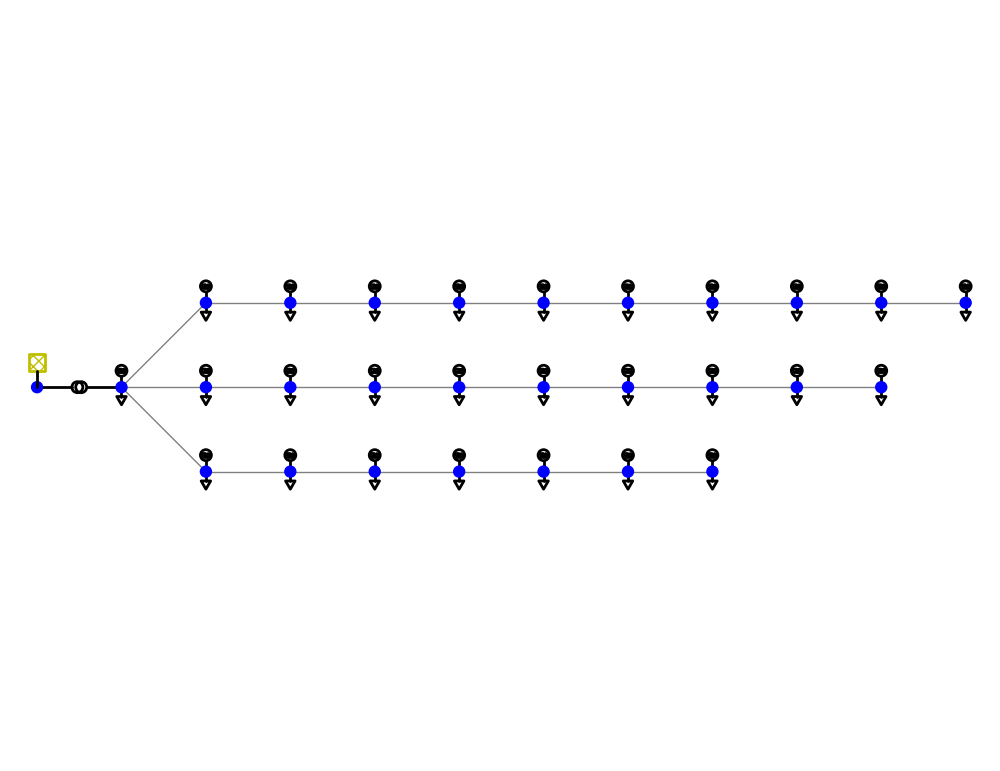

<Axes: >

In [3]:
plot.simple_plot(net, plot_loads=True, plot_sgens=True)

In [4]:
pp.runpp(net)
net.res_ext_grid

NUM_PROFILES = net.load.shape[0]
print(NUM_PROFILES)

27


#### Algorithmic Optimization of Household Allocation

Find and rank the best load-generation pairs based on minimizing peak net load

In [5]:
from rank_best_pairs import rank_best_pairs
ranked_pairs = rank_best_pairs(
    gen_data_path=GEN_DATA_PATH,
    load_data_path=LOAD_DATA_PATH,
    num_profiles=NUM_PROFILES
)
print("Ranked load-generation pairs (best to worst):")
print(ranked_pairs)

Ranked load-generation pairs (best to worst):
[(18, 20), (8, 15), (12, 8), (11, 10), (15, 16), (23, 24), (1, 9), (5, 6), (9, 3), (6, 2), (25, 25), (0, 17), (16, 11), (20, 1), (17, 26), (14, 5), (3, 0), (2, 13), (24, 18), (21, 23), (4, 4), (7, 7), (22, 21), (10, 19), (19, 14), (13, 12), (26, 22)]


Rank a list of buses from "weakest" to "strongest" using the Short Circuit Impedance Method.

In [6]:
from grid_analyzer import rank_buses_by_impedance
residential_bus_indicies = list(range(1, NUM_PROFILES+1))  # buses 1 to 17 (excluding bus 0 which is the external grid)
ranked_buses = rank_buses_by_impedance(net, residential_bus_indicies)

Ranking buses by Short-Circuit Impedance (z_sc)...
Ranked Buses (Weakest to Strongest): [26, 16, 25, 15, 24, 14, 7, 23, 13, 6, 22, 12, 5, 21, 11, 4, 20, 3, 10, 19, 9, 2, 18, 8, 1, 17, 0]


Assign best load generation pairs to weakest bus. Create the "smart" allocation and calculate its sum of max loadings.

In [7]:
from first_guesses import create_smart_seed, create_round_robin_seed
from genetic_algorithm import calculate_fitness
smart_seed_allocation = create_smart_seed(
    ranked_pairs,
    ranked_buses
)

fitness_smart, max_smart = calculate_fitness(
    smart_seed_allocation,
    net,
    gen_data_path=GEN_DATA_PATH,
    load_data_path=LOAD_DATA_PATH
)
print(f"Smart Seed sum of max loadings: ", max_smart)

No time steps to calculate are specified. I'll check the datasource of the first controller for avaiable time steps


Creating smart seed allocation...
Smart seed allocation created.
Load Allocation: [26, 19, 7, 2, 14, 16, 6, 1, 10, 4, 24, 17, 0, 9, 23, 11, 8, 13, 22, 21, 3, 20, 25, 5, 15, 12, 18]
Generation Allocation: [22, 14, 7, 13, 5, 11, 2, 9, 19, 4, 18, 26, 17, 3, 24, 10, 15, 12, 21, 23, 0, 1, 25, 6, 16, 8, 20]


100%|██████████| 24/24 [00:00<00:00, 402.09it/s]

Smart Seed sum of max loadings:  114.90931805377357


Run Round Robin Allocation, to see if is gets a better result than Smart Seed Allocation. 

In [8]:
round_robin_allocation = create_round_robin_seed(
    gen_data_path=GEN_DATA_PATH,
    load_data_path=LOAD_DATA_PATH,
    num_profiles=NUM_PROFILES
)
fitness_rr, max_rr = calculate_fitness(
    round_robin_allocation,
    net,
    gen_data_path=GEN_DATA_PATH,
    load_data_path=LOAD_DATA_PATH
)
print(f"Round Robin sum of max loadings: ", max_rr)

No time steps to calculate are specified. I'll check the datasource of the first controller for avaiable time steps
100%|██████████| 24/24 [00:00<00:00, 323.51it/s]


Round Robin sum of max loadings:  107.89595964006418


Run the genetic algorithm for grid B, using best first guess.

In [9]:
# Decide which initial allocation to use
if max_smart < max_rr:
    print("Using Smart Seed as initial allocation for GA.")
    initial_allocation = smart_seed_allocation
else:
    print("Using Round Robin Seed as initial allocation for GA.")
    initial_allocation = round_robin_allocation

from genetic_algorithm import run_genetic_algorithm
run_genetic_algorithm(
    net,
    gen_data_path=GEN_DATA_PATH,
    load_data_path=LOAD_DATA_PATH,
    initial_allocation=initial_allocation,
    population_size=200,
    num_generations=50,
    tournament_size=20,
    mutation_rate=0.15,
    crossover_rate=0.9
)


No time steps to calculate are specified. I'll check the datasource of the first controller for avaiable time steps


Using Round Robin Seed as initial allocation for GA.
--- Distribution Grid Genetic Algorithm Optimization Test ---
Distribution Grid:
 This pandapower network includes the following parameter tables:
   - bus (28 elements)
   - load (27 elements)
   - sgen (27 elements)
   - ext_grid (1 element)
   - line (26 elements)
   - trafo (1 element)
   - controller (4 elements)
   - bus_geodata (28 elements)
   - output_writer (1 element)
 and the following results tables:
   - res_bus (28 elements)
   - res_line (26 elements)
   - res_trafo (1 element)
   - res_ext_grid (1 element)
   - res_load (27 elements)
   - res_sgen (27 elements)
   - res_bus_sc (27 elements)
   - res_line_sc (26 elements)
   - res_trafo_sc (1 element)
   - res_ext_grid_sc (1 element)
   - res_sgen_sc (27 elements)
ERROR: Grid must have exactly 17 load/generation nodes.

Base Allocation Test:
Load Allocation: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26]
Generation A

100%|██████████| 24/24 [00:00<00:00, 237.03it/s]
No time steps to calculate are specified. I'll check the datasource of the first controller for avaiable time steps


Fitness: 0.007236663708455094, Sum Max Loading: 138.18522461277715

Initial Allocation Test:
Load Allocation: [13, 18, 12, 26, 14, 2, 11, 21, 9, 8, 10, 4, 3, 1, 20, 22, 17, 7, 15, 0, 16, 5, 25, 6, 24, 23, 19]
Generation Allocation: [13, 18, 12, 26, 14, 2, 11, 21, 9, 8, 10, 4, 3, 1, 20, 22, 17, 7, 15, 0, 16, 5, 25, 6, 24, 23, 19]


100%|██████████| 24/24 [00:00<00:00, 223.05it/s]


Fitness: 0.009268187644245, Sum Max Loading: 107.89595964006418

=== Distribution Grid Genetic Algorithm Optimization ===
CPUs available: 12
Using 200 allocations, evolving for 50 generations.
Creating initial population...

--- Generation 1 / 50 ---
Evaluationg 200 allocations...
Best Allocation: ([7, 11, 1, 19, 13, 24, 20, 2, 16, 26, 6, 22, 14, 3, 9, 17, 25, 12, 18, 10, 8, 21, 0, 5, 4, 15, 23], [25, 6, 20, 3, 19, 17, 21, 10, 4, 5, 1, 14, 0, 7, 26, 2, 24, 16, 15, 13, 22, 18, 8, 12, 11, 23, 9]), Fitness: 0.010134426962007831, Sum Max Loading: 98.67356129249562
***New overall best allocation found! Max Loading: 98.67356129249562 ***
New Population: [([7, 11, 1, 19, 13, 24, 20, 2, 16, 26, 6, 22, 14, 3, 9, 17, 25, 12, 18, 10, 8, 21, 0, 5, 4, 15, 23], [25, 6, 20, 3, 19, 17, 21, 10, 4, 5, 1, 14, 0, 7, 26, 2, 24, 16, 15, 13, 22, 18, 8, 12, 11, 23, 9]), ([7, 3, 8, 2, 20, 26, 21, 4, 0, 10, 15, 14, 22, 1, 16, 18, 5, 19, 17, 11, 13, 23, 24, 9, 12, 6, 25], [3, 20, 19, 16, 6, 10, 25, 13, 18, 21, 1

Plot how the best sum of max loadings evolves over the generations. This can be used for tuning the GA algorithm.

Loading most recent run: GA runs C\ga_run_C_20251117_223544.json


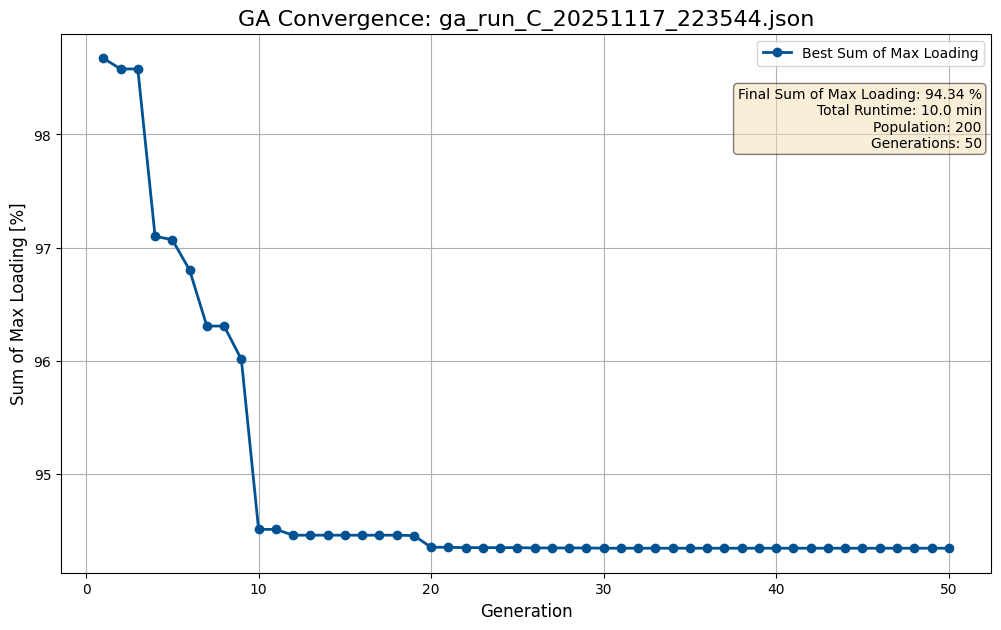

In [10]:
import matplotlib.pyplot as plt
import json 
from pathlib import Path
import glob

run_directory = Path("./GA runs C/")
# Find all JSON files in the directory matching the pattern
search_pattern = str(run_directory / "ga_run_C_*.json")
all_run_files = glob.glob(search_pattern)

if not all_run_files:
    print("No GA run files found.")
else:
    # Find the most recent file
    try:
        latest_file = max(all_run_files)
        print(f"Loading most recent run: {latest_file}")
    except Exception as e:
        print(f"Error finding the most recent file: {e}")
    
    try: 
        # Load and parse that data
        with open(latest_file, 'r') as f:
            data = json.load(f)

        # The 'generation_logs' key contains the list of data points
        logs = data.get('generation_logs')

        if not logs:
            print("Error: JSON file does not contain 'generation_logs' key or it is empty.")
        else:
            # Convert to a DataFrame for easier plotting
            df = pd.DataFrame(logs)
            
            # Calculate the *true* convergence
            # 'best_loading' is the best for that generation
            df['overall_best_loading'] = df['best_loading'].cummin()

            # Create the plot
            fig, ax = plt.subplots(figsize=(12, 7))
            
            # Plot the overall best (solid line)
            ax.plot(df['generation'], df['overall_best_loading'], 
                         linestyle='-', 
                         marker='o', 
                         color='#005293', 
                         linewidth=2, 
                         label='Best Sum of Max Loading')
            
            # Add title and labels
            ax.set_title(f"GA Convergence: {Path(latest_file).name}", fontsize=16)
            ax.set_xlabel("Generation", fontsize=12)
            ax.set_ylabel("Sum of Max Loading [%]", fontsize=12)
            ax.legend(fontsize=10)
            ax.grid(True)
                
            # Add a text box with final results from the top-level keys
            final_best = data.get('overall_best_loading', 0)
            run_time = data.get('runtime_seconds', 0)
            pop_size = data.get('pop_size', 'N/A')
            num_gen = data.get('num_generations', 'N/A')
                
            text_str = (
                f"Final Sum of Max Loading: {final_best:.2f} %\n"
                f"Total Runtime: {run_time / 60:.1f} min\n"
                f"Population: {pop_size}\n"
                f"Generations: {num_gen}"
            )

            # Place a text box in upper right in axes coords
            props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
            ax.text(0.99, 0.90, text_str, 
                     transform=ax.transAxes, 
                     fontsize=10,
                     verticalalignment='top', 
                     horizontalalignment='right', 
                     bbox=props)
            
            # Save the plot 
            plt.savefig('../Figures/GA_Convergence_latest_run.png', dpi=300)
            # 8. Show the plot in a new window
            plt.show()

    except json.JSONDecodeError as e:
        print(f"Error decoding JSON from file {latest_file}: {e}")
    except Exception as e:
        print(f"Error loading or processing file {latest_file}: {e}")
